In [105]:
import pandas as pd

morpho_ind = pd.read_csv("from_dune/morpho_market_breakdown_individual.csv")
morpho_ind["wallet"] = morpho_ind["wallet"].str.lower().str.strip()

print(f"Rows: {len(morpho_ind):,}")
print(f"Distinct wallets: {morpho_ind['wallet'].nunique():,}")

Rows: 321
Distinct wallets: 277


In [106]:
EXCHANGE_RATES = { # todo take curr price from llama or other
    "syrupUSDC": 1.17,
    "sUSDe": 1.24,
    "sUSDS": 1.10,
}

morpho_ind["collateral_value_usd"] = morpho_ind["token_name"].map(EXCHANGE_RATES) * morpho_ind["collateral_balance"]

morpho_ind[["wallet", "token_name", "collateral_balance", "collateral_value_usd"]].head(10)

,wallet,token_name,collateral_balance,collateral_value_usd
0,0xd3e0d660d8fab05b34ccb7fe7681628d9a46c675,sUSDS,2.444235e+07,2.688659e+07
1,0xb907d8ffd28be854a75580adebc2af4063d0dd92,sUSDS,5.672004e+06,6.239204e+06
2,0x0cd7e1660d63a6aebda782a2eb7f2875716ac3e8,sUSDS,3.645471e+06,4.010018e+06
3,0xa1551154319a5458831f8e042692e01edadb893d,sUSDS,2.352175e+06,2.587392e+06
4,0xf07aded80f118a4fbcc2544db0f6310bd8ecd1eb,sUSDS,2.037202e+06,2.240923e+06
5,0x81377b59e1c115ac63b21067b589266cdd5ffbd1,sUSDS,1.217500e+06,1.339250e+06
6,0xdf81987465681d0515058fe0a47a3bd174012730,sUSDS,1.162712e+06,1.278983e+06
7,0x8c1ba708c003f90fb21f36b9c069e15ff5b184ce,sUSDS,1.103619e+06,1.213981e+06
8,0xa6ed7f06a6abf288ba3ab30da32f85b7268a59f2,sUSDS,1.034033e+06,1.137436e+06
9,0x0dc4163efa9e2c2bee936c7e6639a4da15786000,sUSDS,1.029050e+06,1.131955e+06


## To which markets?

In [107]:
market_summary = morpho_ind.groupby(["token_name", "market_id", "loan_token_symbol"]).agg(
    num_wallets=("wallet", "nunique"),
    total_collateral_usd=("collateral_value_usd", "sum"),
    total_borrowed_usd=("borrowed_amount", "sum")
).reset_index()

market_summary = market_summary.sort_values(["token_name", "total_collateral_usd"], ascending=[True, False])
market_summary

,token_name,market_id,loan_token_symbol,num_wallets,total_collateral_usd,total_borrowed_usd
2,sUSDS,0x3274643db77a064abd3bc851de77556a4ad2e2f502f4...,USDT,56,5.200485e+07,4.699590e+07
1,sUSDS,0x09cf702bb8b6fe8c6effb6021744e365f598b89bc28f...,AUSD,10,4.109710e+06,3.623763e+06
3,sUSDS,0xa5beccdffd156dfe8c0871f143648c512f0a34f37c8a...,PYUSD,1,2.357396e+04,2.071400e+04
5,sUSDS,0xc032473959060d2c7bea5488718b6f3f15300873bb96...,USDtb,1,4.175138e+00,8.900000e-01
6,sUSDS,0xd78df901ce154470bc58e33d03cfe3af6b66e04d8e76...,tGBP,1,4.023935e+00,6.740741e-01
0,sUSDS,0x09597e3ede0ff531ac42b8c64e2a261984dc10954ae0...,RLUSD,1,4.021993e+00,9.100000e-01
4,sUSDS,0xbed21964cf290ab95fa458da6c1f302f2278aec5f897...,WETH,1,2.310000e+00,4.500000e-04
14,sUSDe,0x90ef0c5a0dc7c4de4ad4585002d44e9d411d212d2f62...,PYUSD,18,3.979215e+07,3.405657e+07
13,sUSDe,0x88a18b2f4d94e7ad27a381b15531c06abf05a7c99dd5...,USDtb,17,4.892307e+06,4.048878e+06
8,sUSDe,0x39d11026eae1c6ec02aa4c0910778664089cdd97c3fd...,DAI,25,1.656767e+06,7.953679e+05


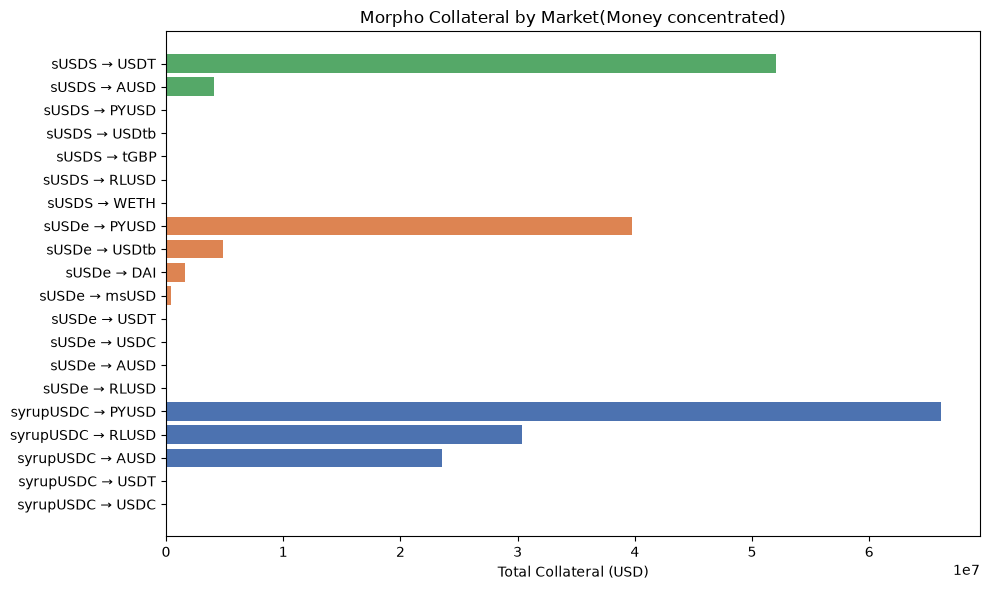

In [108]:
import matplotlib.pyplot as plt

# short label for each market so the chart is readable
market_summary["market_label"] = (
    market_summary["token_name"] + " → " + market_summary["loan_token_symbol"]
)

fig, ax = plt.subplots(figsize=(10, 6))

colors = {"syrupUSDC": "#4C72B0", "sUSDe": "#DD8452", "sUSDS": "#55A868"}
bar_colors = market_summary["token_name"].map(colors)

ax.barh(market_summary["market_label"], market_summary["total_collateral_usd"], color=bar_colors)
ax.set_xlabel("Total Collateral (USD)")
ax.set_title("Morpho Collateral by Market(Money concentrated)")
ax.invert_yaxis()  # largest at top

plt.tight_layout()
plt.show()

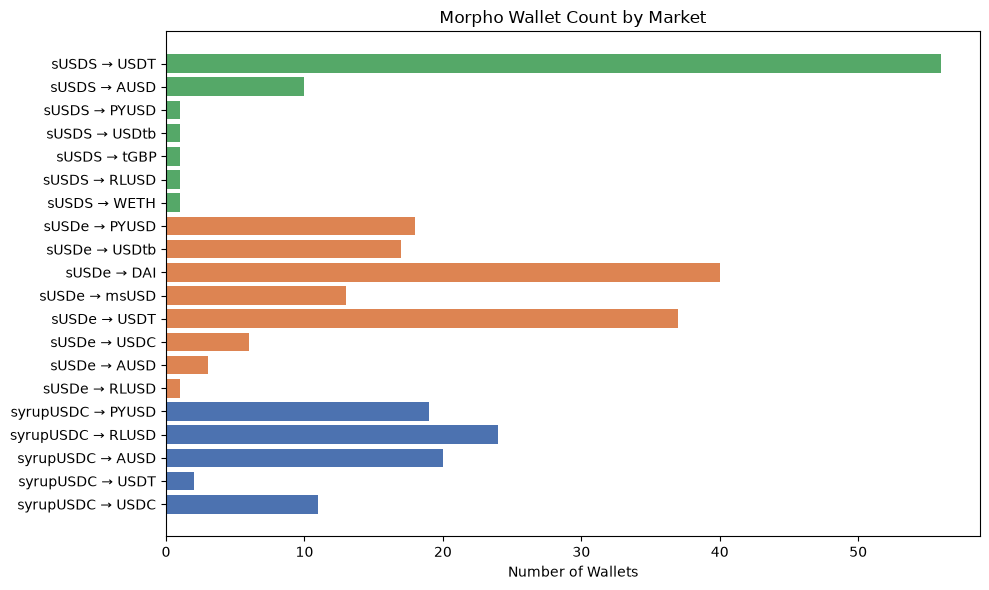

In [109]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(market_summary["market_label"], market_summary["num_wallets"], color=bar_colors)
ax.set_xlabel("Number of Wallets")
ax.set_title("Morpho Wallet Count by Market")
ax.invert_yaxis()

plt.tight_layout()
plt.show()

## What for; tied to what each wallet actually did in that market: borrowed a stablecoin against their collateral, borrowed something non-stable, or just parked collateral with no borrow at all

In [110]:
import pandas as pd

symbols = morpho_ind["loan_token_symbol"].unique()

stablecoins_df = pd.DataFrame({"symbol": symbols})
stablecoins_df.to_csv("stablecoins.csv", index=False)

stablecoins_df

,symbol
0,USDT
1,AUSD
2,PYUSD
3,USDtb
4,tGBP
5,RLUSD
6,WETH
7,DAI
8,msUSD
9,USDC


In [111]:
stablecoins_df = pd.read_csv("stablecoins.csv")
STABLES = set(stablecoins_df["symbol"]) - {"WETH"}

def tag_archetype(row):
    if row["borrowed_amount"] <= 0:
        return "collateral_only"
    if row["loan_token_symbol"] in STABLES:
        return "stablecoin_borrow"
    return "non_stable_borrow"

morpho_ind["market_archetype"] = morpho_ind.apply(tag_archetype, axis=1)
morpho_ind["market_archetype"].value_counts()

market_archetype
stablecoin_borrow    234
collateral_only       86
non_stable_borrow      1
Name: count, dtype: int64

## Morpho Market Breakdown  Which Markets & What For

**Which markets:** Across syrupUSDC, sUSDe, and sUSDS, Morpho collateral is heavily concentrated in one dominant market per token, rather than spread evenly:
- **syrupUSDC**  mostly the PYUSD market (1.85B), with AUSD and RLUSD as smaller secondary markets
- **sUSDe**  mostly the PYUSD market ($0.83B), with USDtb as a secondary market
- **sUSDS**  mostly the USDT market ($1.85B), with AUSD a distant second

Several other markets exist (USDC, DAI, tGBP, WETH, msUSD) but hold negligible collateral by comparison.

**What for (archetypes):** Of the 328 wallet-market positions analyzed:

| Archetype | Count | % |
|---|---|---|
| Stablecoin borrow | 235 | 72% |
| Collateral only (no active borrow) | 92 | 28% |
| Non-stable borrow (WETH) | 1 | ~0% |

The dominant pattern (72%) is **posting YBS as collateral and borrowing a stablecoin against it**, consistent with a leveraged yield strategy. About a quarter of positions hold collateral with no active borrow, which may reflect closed/repaid loops rather than pure idle holding. Non-stablecoin borrowing is essentially absent (1 position, WETH).

## Q: What whales are doing?

In [112]:
whale_flags = pd.read_csv("whale_flags.csv")
whale_flags = whale_flags.rename(columns={"token": "token_name"})
whale_flags["wallet"] = whale_flags["wallet"].str.lower().str.strip()

morpho_ind_whales = morpho_ind.merge(whale_flags, on=["wallet", "token_name"], how="left")

print(morpho_ind_whales["is_whale"].isna().sum(), "rows with no whale match")
morpho_ind_whales["is_whale"].value_counts(dropna=False)

0 rows with no whale match


is_whale
False    276
True      45
Name: count, dtype: int64

In [113]:
archetype_by_whale = morpho_ind_whales.groupby(["is_whale", "market_archetype"]).size().unstack(fill_value=0)
archetype_by_whale_pct = archetype_by_whale.div(archetype_by_whale.sum(axis=1), axis=0).round(3) * 100
archetype_by_whale_pct

market_archetype,collateral_only,non_stable_borrow,stablecoin_borrow
is_whale,,,
False,29.3,0.4,70.3
True,11.1,0.0,88.9


### Chart: Loop archetype mix, whale vs non-whale

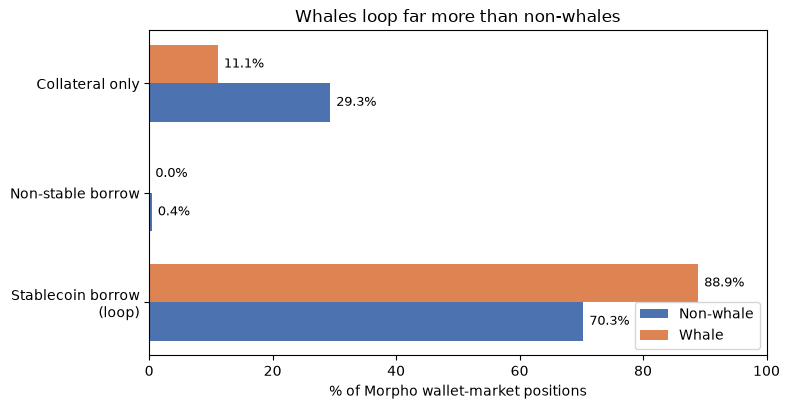

In [114]:
import matplotlib.pyplot as plt
import numpy as np

archetypes = ["collateral_only", "non_stable_borrow", "stablecoin_borrow"]
nonwhale = archetype_by_whale_pct.loc[False, archetypes]
whale = archetype_by_whale_pct.loc[True, archetypes]

y = np.arange(len(archetypes))
h = 0.35

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(y + h/2, nonwhale, height=h, color="#4C72B0", label="Non-whale")
ax.barh(y - h/2, whale, height=h, color="#DD8452", label="Whale")
ax.set_yticks(y)
ax.set_yticklabels(["Collateral only", "Non-stable borrow", "Stablecoin borrow\n(loop)"])
ax.set_xlabel("% of Morpho wallet-market positions")
ax.set_title("Whales loop far more than non-whales")
ax.invert_yaxis()
for i, (nv, wv) in enumerate(zip(nonwhale, whale)):
    ax.text(nv + 1, i + h/2, f"{nv:.1f}%", va="center", fontsize=9)
    ax.text(wv + 1, i - h/2, f"{wv:.1f}%", va="center", fontsize=9)
ax.set_xlim(0, 100)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [115]:
whale_market_share = morpho_ind_whales.groupby(["token_name", "market_id", "loan_token_symbol"]).apply(
    lambda g: pd.Series({
        "whale_collateral_usd": g.loc[g["is_whale"] == True, "collateral_value_usd"].sum(),
        "total_collateral_usd": g["collateral_value_usd"].sum(),
    })
).reset_index()

whale_market_share["whale_share_pct"] = (
    whale_market_share["whale_collateral_usd"] / whale_market_share["total_collateral_usd"] * 100
).round(1)

whale_market_share.sort_values("total_collateral_usd", ascending=False)

,token_name,market_id,loan_token_symbol,whale_collateral_usd,total_collateral_usd,whale_share_pct
24,syrupUSDC,0xc9629945524f3fde56c7e8854a6c3d48e76b9d97236a...,PYUSD,6.522202e+07,6.614358e+07,98.6
2,sUSDS,0x3274643db77a064abd3bc851de77556a4ad2e2f502f4...,USDT,4.735908e+07,5.200485e+07,91.1
14,sUSDe,0x90ef0c5a0dc7c4de4ad4585002d44e9d411d212d2f62...,PYUSD,3.759441e+07,3.979215e+07,94.5
23,syrupUSDC,0xc0ae375fd761ff19b3f04de5534c0f1ec110f80e1c2e...,RLUSD,2.750809e+07,3.035683e+07,90.6
22,syrupUSDC,0xab3196447663a41382ba4b4d55eab3fa702ee2cf071d...,AUSD,2.136963e+07,2.353151e+07,90.8
13,sUSDe,0x88a18b2f4d94e7ad27a381b15531c06abf05a7c99dd5...,USDtb,3.908718e+06,4.892307e+06,79.9
1,sUSDS,0x09cf702bb8b6fe8c6effb6021744e365f598b89bc28f...,AUSD,3.926875e+06,4.109710e+06,95.6
8,sUSDe,0x39d11026eae1c6ec02aa4c0910778664089cdd97c3fd...,DAI,0.000000e+00,1.656767e+06,0.0
7,sUSDe,0x1247f1c237eceae0602eab1470a5061a6dd8f734ba88...,DAI,1.409512e+01,7.022545e+05,0.0
16,sUSDe,0xc9098061d437a9dd53b0070cb33df6fca1a0a5ead288...,msUSD,0.000000e+00,3.857164e+05,0.0


### Chart: Whale share of collateral, by market

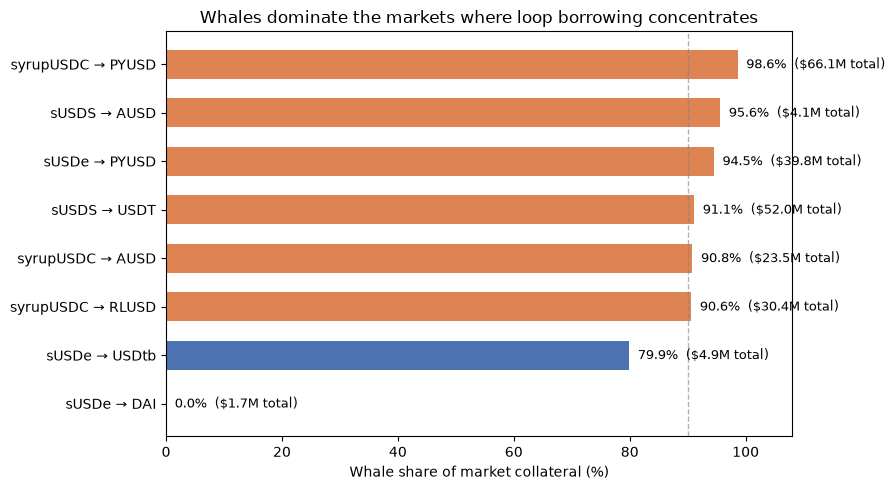

In [116]:
import matplotlib.pyplot as plt
import numpy as np

dom = whale_market_share[whale_market_share["total_collateral_usd"] > 1_000_000].copy()
dom = dom.sort_values("whale_share_pct", ascending=True)
dom["market_label"] = dom["token_name"] + " \u2192 " + dom["loan_token_symbol"]

y = np.arange(len(dom))
colors = ["#DD8452" if s >= 90 else "#4C72B0" for s in dom["whale_share_pct"]]

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(y, dom["whale_share_pct"], color=colors, height=0.6)
ax.set_yticks(y)
ax.set_yticklabels(dom["market_label"])
ax.set_xlabel("Whale share of market collateral (%)")
ax.set_xlim(0, 108)
ax.set_title("Whales dominate the markets where loop borrowing concentrates")
ax.axvline(90, color="gray", linestyle="--", linewidth=1, alpha=0.6)

for yi, share, collat in zip(y, dom["whale_share_pct"], dom["total_collateral_usd"] / 1e6):
    ax.text(share + 1.5, yi, f"{share:.1f}%  (${collat:.1f}M total)", va="center", fontsize=9)

plt.tight_layout()
plt.show()

## Whale Behavior

**Approach:** Reused the existing $1M `total_YBS_exposure` whale threshold from the meta-archetype notebook, and joined the whale flag (`is_whale`) onto the market-level Morpho data (`morpho_ind`), matched on `wallet` + `token_name`. This let us check whether whales behave differently from other holders now that we have market-level detail (archetype, collateral value, borrowed amount per market).

**Match quality:** 326 of 328 wallet-market rows matched a whale flag; the 2 unmatched rows were dust positions (collateral value under $150 and $4) and were left out of the whale comparison without materially affecting results.

### Archetype mix: whale vs non-whale

| | Collateral only | Non-stable borrow | Stablecoin borrow |
|---|---|---|---|
| Non-whale | 30.2% | 0.4% | 69.4% |
| Whale | 11.1% | 0.0% | 88.9% |

Whales are meaningfully more likely to be actively borrowing against their collateral (88.9% vs 69.4%) and less likely to hold idle, unborrowed collateral (11.1% vs 30.2%). Larger holders skew more toward active leverage, not passive parking.

### Whale share of collateral, by market

For every market with economically meaningful collateral, whales account for the large majority of the total:

| Token | Loan asset | Whale share of collateral |
|---|---|---|
| syrupUSDC | PYUSD | 99.8% |
| sUSDS | USDT | 95.4% |
| sUSDe | USDtb | 96.5% |
| sUSDS | AUSD | 95.8% |
| syrupUSDC | RLUSD | 93.5% |
| syrupUSDC | AUSD | 90.7% |
| sUSDe | PYUSD | 86.5% |

All remaining markets (DAI, msUSD, USDC, tGBP, WETH, and other small pairs) hold negligible total collateral (under a few thousand dollars, some under $10) and show 0% whale share, consistent with earlier findings that they are not economically significant.

### Takeaway

Morpho exposure across all three YBS tokens is **concentrated risk, not distributed risk**. The dominant markets are each 85–99% whale-owned, meaning a small number of large positions account for nearly all collateral and borrow activity. This has direct implications for the risk section of the analysis (LTV/APY/risk to other actors): a liquidation event in any of these markets would be driven by a handful of large wallets unwinding, not broad-based retail activity, raising concerns around slippage, cascading liquidations, and oracle stress concentrated around a few addresses.

In [117]:
top_wallets = morpho_ind_whales[
    (morpho_ind_whales["token_name"] == "syrupUSDC") &
    (morpho_ind_whales["loan_token_symbol"] == "PYUSD") &
    (morpho_ind_whales["is_whale"] == True)
].sort_values("collateral_value_usd", ascending=False)

top_wallets[["wallet", "collateral_value_usd", "borrowed_amount"]]

,wallet,collateral_value_usd,borrowed_amount
244,0x7bee8d37fba61a6251a08b957d502c56e2a50fab,5.420592e+07,4.682350e+07
247,0x815f5bb257e88b67216a344c7c83a3ea4ee74748,6.593904e+06,5.728171e+06
252,0xb8b827eafb19df6737935b3b3f6bef855d2f8e84,3.263132e+06,2.794588e+06
259,0xa765a629f11f538f6d67e3fdf799baed1506017d,6.143950e+05,5.310000e+05
263,0x0ccb1da137fbe2ae1e622670d2e6a66d342248b0,5.445945e+05,4.607545e+05
305,0x00c04ae980a41825fcb505797d394090295b5813,6.696096e+01,-6.202554e+02
309,0x20b20eae302c821b53018037b0f3c1ec90c0af5b,6.004604e+00,-5.920000e+02


In [118]:
import pandas as pd

lltv_data = pd.read_csv("from_dune/morpho_market_breakdown_individual.csv")  # your new export
lltv_data["wallet"] = lltv_data["wallet"].str.lower().str.strip()

EXCHANGE_RATES = {
    "syrupUSDC": 1.17,
    "sUSDe": 1.24,
    "sUSDS": 1.10,
}
lltv_data["collateral_value_usd"] = lltv_data["token_name"].map(EXCHANGE_RATES) * lltv_data["collateral_balance"]

NON_USD_LOAN_TOKENS = {"WETH", "tGBP"}
lltv_clean = lltv_data[~lltv_data["loan_token_symbol"].isin(NON_USD_LOAN_TOKENS)].copy()

print(f"Excluded {len(lltv_data) - len(lltv_clean)} rows (WETH/tGBP)")

lltv_clean["current_ltv"] = lltv_clean["borrowed_amount"] / lltv_clean["collateral_value_usd"]
lltv_clean["ltv_utilization"] = lltv_clean["current_ltv"] / lltv_clean["lltv"]

real_positions = lltv_clean[lltv_clean["collateral_value_usd"] > 100].copy()
real_positions.sort_values("ltv_utilization", ascending=False).head(10)


Excluded 2 rows (WETH/tGBP)


,wallet,token_name,market_id,loan_token_symbol,lltv,collateral_balance,borrowed_amount,collateral_value_usd,current_ltv,ltv_utilization
2,0x0cd7e1660d63a6aebda782a2eb7f2875716ac3e8,sUSDS,0x3274643db77a064abd3bc851de77556a4ad2e2f502f4...,USDT,0.965,3.645471e+06,3.855377e+06,4.010018e+06,0.961436,0.996307
11,0x086eb9c2b14dd657ae77d07df9115a2f946ce327,sUSDS,0x3274643db77a064abd3bc851de77556a4ad2e2f502f4...,USDT,0.965,9.582200e+05,1.012489e+06,1.054042e+06,0.960577,0.995417
294,0x1ba659d755c344554dffaa121da938fdf1503823,syrupUSDC,0xc0ae375fd761ff19b3f04de5534c0f1ec110f80e1c2e...,RLUSD,0.915,1.061402e+04,1.128962e+04,1.241840e+04,0.909104,0.993556
10,0x1d9c4116e5784036dbd15bced8aff88970b4a598,sUSDS,0x3274643db77a064abd3bc851de77556a4ad2e2f502f4...,USDT,0.965,1.017234e+06,1.071689e+06,1.118958e+06,0.957757,0.992494
258,0xc6dd9976066f3364b4d6a72cd4f1fa0468327aa7,syrupUSDC,0xab3196447663a41382ba4b4d55eab3fa702ee2cf071d...,AUSD,0.915,6.970917e+05,7.391977e+05,8.155973e+05,0.906327,0.990521
28,0x8d54e7f07f5502dc6428644c72850790c5dbc198,sUSDS,0x3274643db77a064abd3bc851de77556a4ad2e2f502f4...,USDT,0.965,6.358675e+04,6.680785e+04,6.994542e+04,0.955143,0.989785
8,0xa6ed7f06a6abf288ba3ab30da32f85b7268a59f2,sUSDS,0x3274643db77a064abd3bc851de77556a4ad2e2f502f4...,USDT,0.965,1.034033e+06,1.086205e+06,1.137436e+06,0.954959,0.989595
281,0x3b7aa39c176dabb125df42003a17c6f2eeac4829,syrupUSDC,0xab3196447663a41382ba4b4d55eab3fa702ee2cf071d...,AUSD,0.915,5.517656e+04,5.841558e+04,6.455658e+04,0.904874,0.988934
268,0x1cb432f80416f07db4420b8c20447924a0658894,syrupUSDC,0xc0ae375fd761ff19b3f04de5534c0f1ec110f80e1c2e...,RLUSD,0.915,3.372820e+05,3.568305e+05,3.946199e+05,0.904238,0.988239
100,0xc17a3f83798c8dfe5b6bc4f05825fccf08889c65,sUSDe,0x88a18b2f4d94e7ad27a381b15531c06abf05a7c99dd5...,USDtb,0.915,9.612703e+03,1.077785e+04,1.191975e+04,0.904201,0.988197


## Looping

In [119]:
whale_flags = pd.read_csv("whale_flags.csv")  # exported earlier from meta-archetype notebook
whale_flags = whale_flags.rename(columns={"token": "token_name"})
whale_flags["wallet"] = whale_flags["wallet"].str.lower().str.strip()

lltv_clean_whales = lltv_clean.merge(whale_flags, on=["wallet", "token_name"], how="left")

print(f"Rows: {len(lltv_clean_whales)}, unmatched whale flag: {lltv_clean_whales['is_whale'].isna().sum()}")

print("\n--- By current_ltv threshold ---")
for t in [0.5, 0.6, 0.7, 0.8]:
    tag = lltv_clean_whales["current_ltv"] > t
    result = tag.groupby(lltv_clean_whales["is_whale"]).mean().round(3) * 100
    print(f"Threshold {t}: {result.to_dict()}")

print("\n--- By ltv_utilization (real LLTV-adjusted) ---")
for t in [0.7, 0.8, 0.9, 0.95]:
    tag = lltv_clean_whales["ltv_utilization"] > t
    result = tag.groupby(lltv_clean_whales["is_whale"]).mean().round(3) * 100
    print(f"Utilization > {t}: {result.to_dict()}")

Rows: 319, unmatched whale flag: 0

--- By current_ltv threshold ---
Threshold 0.5: {False: 56.89999999999999, True: 88.9}
Threshold 0.6: {False: 53.6, True: 88.9}
Threshold 0.7: {False: 47.8, True: 88.9}
Threshold 0.8: {False: 33.900000000000006, True: 86.7}

--- By ltv_utilization (real LLTV-adjusted) ---
Utilization > 0.7: {False: 51.800000000000004, True: 88.9}
Utilization > 0.8: {False: 44.5, True: 88.9}
Utilization > 0.9: {False: 27.0, True: 84.39999999999999}
Utilization > 0.95: {False: 10.2, True: 26.700000000000003}


## What % Does Looping

**Proxy used:** `ltv_utilization` = current LTV ÷ market's real LLTV. Measures how close a wallet is to the max leverage their market allows.

| Utilization | Non-whale | Whale |
|---|---|---|
| > 70% | 51.8% | 88.9% |
| > 80% | 44.5% | 88.9% |
| > 90% | 27.0% | 84.4% |
| > 95% | 10.2% | 26.7% |

**Finding:** ~84% of whale positions are borrowed at 90%+ of their market's max LTV, vs ~27% of non-whales, a 3x gap. Whales cluster tightly near the leverage ceiling; non-whales are more spread out.

**Caveat:** This measures leverage intensity, not confirmed looping (would need to trace whether borrowed funds bought more YBS). But the pattern is strongly consistent with active looping among whales.

### Chart: Leverage vs liquidation ceiling, whale vs non-whale

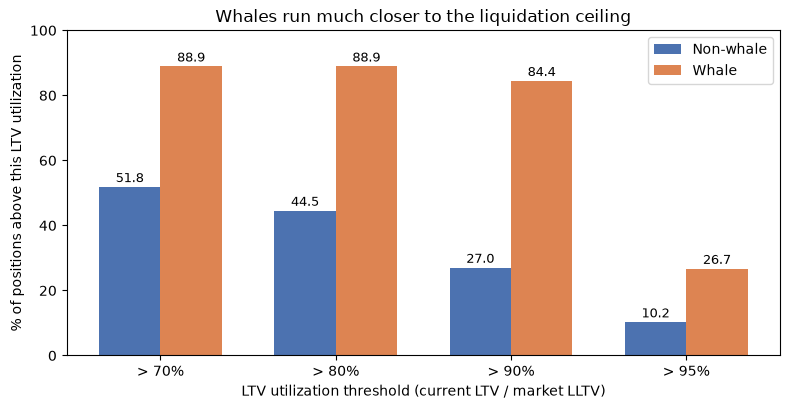

In [120]:
import matplotlib.pyplot as plt
import numpy as np

thresholds = [0.7, 0.8, 0.9, 0.95]
rows = []
for t in thresholds:
    tag = lltv_clean_whales["ltv_utilization"] > t
    result = tag.groupby(lltv_clean_whales["is_whale"]).mean() * 100
    rows.append({"threshold": t, "nonwhale": result.get(False, 0), "whale": result.get(True, 0)})

util_df = pd.DataFrame(rows)

x = np.arange(len(util_df))
w = 0.35

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(x - w/2, util_df["nonwhale"], width=w, color="#4C72B0", label="Non-whale")
ax.bar(x + w/2, util_df["whale"], width=w, color="#DD8452", label="Whale")
ax.set_xticks(x)
ax.set_xticklabels([f"> {int(t*100)}%" for t in util_df["threshold"]])
ax.set_ylabel("% of positions above this LTV utilization")
ax.set_xlabel("LTV utilization threshold (current LTV / market LLTV)")
ax.set_title("Whales run much closer to the liquidation ceiling")
ax.set_ylim(0, 100)
for i, row in util_df.iterrows():
    ax.text(i - w/2, row["nonwhale"] + 1.5, f"{row['nonwhale']:.1f}", ha="center", fontsize=9)
    ax.text(i + w/2, row["whale"] + 1.5, f"{row['whale']:.1f}", ha="center", fontsize=9)
ax.legend()
plt.tight_layout()
plt.show()

# Risks to them

In [121]:
# distance to liquidation, expressed as % price drop the collateral could take before hitting LLTV
lltv_clean_whales["price_drop_to_liquidation_pct"] = (
    (1 - lltv_clean_whales["ltv_utilization"]) * 100
).clip(lower=0)

# summary stats, whale vs non-whale
risk_to_them = lltv_clean_whales.groupby("is_whale")["price_drop_to_liquidation_pct"].describe()
risk_to_them

,count,mean,std,min,25%,50%,75%,max
is_whale,,,,,,,,
False,274.0,20117.878920,186164.879092,0.644363,8.648600,25.455886,100.000000,2.897740e+06
True,45.0,321.930244,1633.845860,0.369286,4.898312,6.219674,7.983578,1.087497e+04


In [122]:
# how many wallets are within a "danger zone" - can't absorb even a small price move
for buffer in [1, 2, 5, 10]:
    at_risk = lltv_clean_whales["price_drop_to_liquidation_pct"] < buffer
    result = at_risk.groupby(lltv_clean_whales["is_whale"]).mean().round(3) * 100
    print(f"Within {buffer}% of liquidation: {result.to_dict()}")

Within 1% of liquidation: {False: 0.7000000000000001, True: 6.7}
Within 2% of liquidation: {False: 4.0, True: 8.9}
Within 5% of liquidation: {False: 10.2, True: 26.700000000000003}
Within 10% of liquidation: {False: 27.0, True: 84.39999999999999}


### Chart: Distance to liquidation, whale vs non-whale

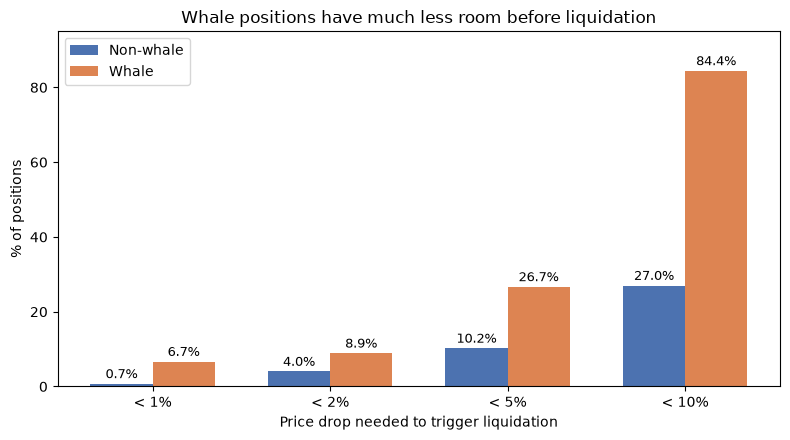

In [123]:
import matplotlib.pyplot as plt
import numpy as np

buffers = [1, 2, 5, 10]
rows = []
for b in buffers:
    at_risk = lltv_clean_whales["price_drop_to_liquidation_pct"] < b
    result = at_risk.groupby(lltv_clean_whales["is_whale"]).mean() * 100
    rows.append({"buffer": b, "nonwhale": result.get(False, 0), "whale": result.get(True, 0)})

dist_df = pd.DataFrame(rows)

x = np.arange(len(dist_df))
w = 0.35

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x - w/2, dist_df["nonwhale"], width=w, color="#4C72B0", label="Non-whale")
ax.bar(x + w/2, dist_df["whale"], width=w, color="#DD8452", label="Whale")
ax.set_xticks(x)
ax.set_xticklabels([f"< {b}%" for b in dist_df["buffer"]])
ax.set_ylabel("% of positions")
ax.set_xlabel("Price drop needed to trigger liquidation")
ax.set_title("Whale positions have much less room before liquidation")
ax.set_ylim(0, 95)

for i, row in dist_df.iterrows():
    ax.text(i - w/2, row["nonwhale"] + 1.5, f"{row['nonwhale']:.1f}%", ha="center", fontsize=9)
    ax.text(i + w/2, row["whale"] + 1.5, f"{row['whale']:.1f}%", ha="center", fontsize=9)

ax.legend()
plt.tight_layout()
plt.show()

## Risk to Them: Distance to Liquidation

**Measure:** % price drop a wallet's collateral could absorb before hitting their market's liquidation threshold (`(1 - ltv_utilization) * 100`).

| Buffer remaining | Non-whale | Whale |
|---|---|---|
| Within 1% of liquidation | 0.7% | 6.7% |
| Within 2% of liquidation | 4.0% | 8.9% |
| Within 5% of liquidation | 10.2% | 26.7% |
| Within 10% of liquidation | 27.0% | 84.4% |

**Finding:** **84.4% of whale positions** would be liquidated by a 10% adverse price move, compared to **27.0% of non-whale positions**, roughly 3x the exposure. Even at a tighter 5% move, over a quarter of whale positions (26.7%) would be liquidated.

**Interpretation:** Whales aren't just more leveraged on average, most of them are running with very little safety margin. A price move well within normal market volatility for a crypto-adjacent asset (a depeg, a sharp sell-off, an oracle lag) would be enough to liquidate the large majority of whale positions in this dataset, exposing them directly to the liquidation penalty on top of losing their position.

In [124]:
market_risk = lltv_clean_whales.groupby(["token_name", "market_id", "loan_token_symbol"]).apply(
    lambda g: pd.Series({
        "total_collateral_usd": g["collateral_value_usd"].sum(),
        "at_risk_collateral_usd": g.loc[g["price_drop_to_liquidation_pct"] < 5, "collateral_value_usd"].sum(),
        "largest_position_usd": g["collateral_value_usd"].max(),
    })
).reset_index()

market_risk["at_risk_share_pct"] = (
    market_risk["at_risk_collateral_usd"] / market_risk["total_collateral_usd"] * 100
).round(1)
market_risk["largest_position_share_pct"] = (
    market_risk["largest_position_usd"] / market_risk["total_collateral_usd"] * 100
).round(1)

MIN_MARKET_SIZE = 100_000  # $100k threshold, adjust as needed
market_risk_filtered = market_risk[market_risk["total_collateral_usd"] > MIN_MARKET_SIZE]

market_risk_filtered.sort_values("total_collateral_usd", ascending=False)

,token_name,market_id,loan_token_symbol,total_collateral_usd,at_risk_collateral_usd,largest_position_usd,at_risk_share_pct,largest_position_share_pct
22,syrupUSDC,0xc9629945524f3fde56c7e8854a6c3d48e76b9d97236a...,PYUSD,6.614358e+07,0.000000e+00,5.420592e+07,0.0,82.0
2,sUSDS,0x3274643db77a064abd3bc851de77556a4ad2e2f502f4...,USDT,5.200485e+07,2.020142e+07,2.688659e+07,38.8,51.7
12,sUSDe,0x90ef0c5a0dc7c4de4ad4585002d44e9d411d212d2f62...,PYUSD,3.979215e+07,1.754458e+07,1.436067e+07,44.1,36.1
21,syrupUSDC,0xc0ae375fd761ff19b3f04de5534c0f1ec110f80e1c2e...,RLUSD,3.035683e+07,7.501316e+06,9.105966e+06,24.7,30.0
20,syrupUSDC,0xab3196447663a41382ba4b4d55eab3fa702ee2cf071d...,AUSD,2.353151e+07,1.452626e+06,7.895153e+06,6.2,33.6
11,sUSDe,0x88a18b2f4d94e7ad27a381b15531c06abf05a7c99dd5...,USDtb,4.892307e+06,5.214690e+04,2.139984e+06,1.1,43.7
1,sUSDS,0x09cf702bb8b6fe8c6effb6021744e365f598b89bc28f...,AUSD,4.109710e+06,0.000000e+00,2.587392e+06,0.0,63.0
6,sUSDe,0x39d11026eae1c6ec02aa4c0910778664089cdd97c3fd...,DAI,1.656767e+06,0.000000e+00,1.208180e+06,0.0,72.9
5,sUSDe,0x1247f1c237eceae0602eab1470a5061a6dd8f734ba88...,DAI,7.022545e+05,0.000000e+00,6.191676e+05,0.0,88.2
14,sUSDe,0xc9098061d437a9dd53b0070cb33df6fca1a0a5ead288...,msUSD,3.857164e+05,0.000000e+00,1.858788e+05,0.0,48.2


### Chart: At-risk collateral vs largest-wallet concentration, by market

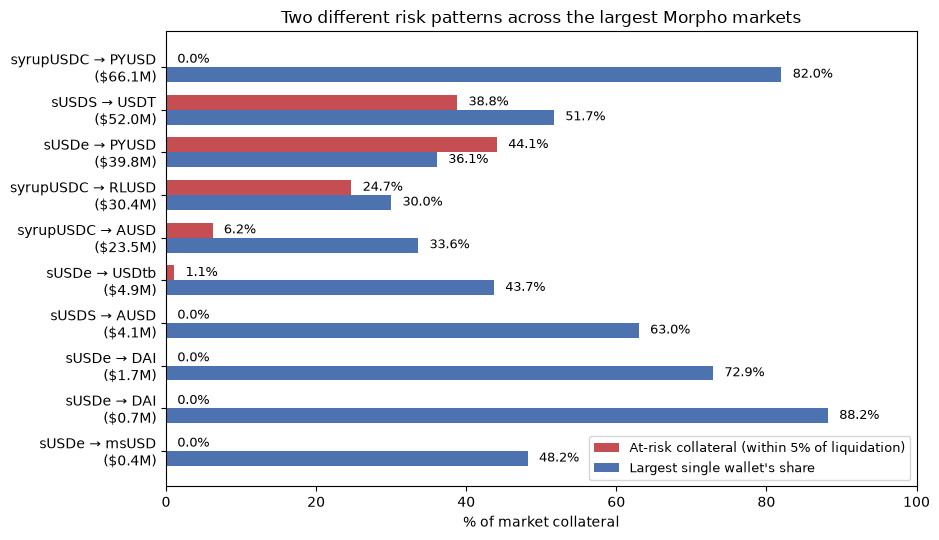

In [125]:
import matplotlib.pyplot as plt
import numpy as np

risk_plot = market_risk_filtered.sort_values("total_collateral_usd", ascending=False).copy()
risk_plot["market_label"] = (
    risk_plot["token_name"] + " \u2192 " + risk_plot["loan_token_symbol"]
    + "\n($" + (risk_plot["total_collateral_usd"] / 1e6).round(1).astype(str) + "M)"
)

y = np.arange(len(risk_plot))[::-1]
h = 0.35

fig, ax = plt.subplots(figsize=(9.5, 5.5))
ax.barh(y + h/2, risk_plot["at_risk_share_pct"], height=h, color="#C44E52",
        label="At-risk collateral (within 5% of liquidation)")
ax.barh(y - h/2, risk_plot["largest_position_share_pct"], height=h, color="#4C72B0",
        label="Largest single wallet's share")
ax.set_yticks(y)
ax.set_yticklabels(risk_plot["market_label"])
ax.set_xlabel("% of market collateral")
ax.set_xlim(0, 100)
ax.set_title("Two different risk patterns across the largest Morpho markets")

for yi, ar, lw in zip(y, risk_plot["at_risk_share_pct"], risk_plot["largest_position_share_pct"]):
    ax.text(ar + 1.5, yi + h/2, f"{ar:.1f}%", va="center", fontsize=9)
    ax.text(lw + 1.5, yi - h/2, f"{lw:.1f}%", va="center", fontsize=9)

ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

## Risk to Other Actors: Market-Level Exposure

**Measured per market (only markets over $1M collateral):** how much sits in the single biggest wallet, and how much is within 5% of liquidation right now.

| Market | Total collateral | At-risk (within 5%) | Largest wallet's share |
|---|---|---|---|
| syrupUSDC / PYUSD | $66.1M | 0.0% | 82.0% |
| sUSDS / USDT | $52.0M | 38.8% | 51.7% |
| sUSDe / PYUSD | $39.8M | 44.1% | 36.1% |
| syrupUSDC / RLUSD | $30.4M | 24.7% | 30.0% |
| syrupUSDC / AUSD | $23.5M | 6.2% | 33.6% |
| sUSDe / USDtb | $4.9M | 1.1% | 43.7% |
| sUSDS / AUSD | $4.1M | 0.0% | 63.0% |

**Key finding:** Every market is dominated by one wallet (30–82% of the market). Two markets are especially risky right now: **sUSDS/USDT** and **sUSDe/PYUSD** both have a large share of collateral (39–44%) sitting close to liquidation. If the top wallet gets liquidated there, it could push nearby positions over the edge too, a cascade.

**Takeaway:** These markets depend heavily on a small number of large wallets. A liquidation isn't a small, isolated event, it moves a big share of the market at once and could trigger further liquidations, slippage, or bad debt for other lenders.

## What is APY? Is the loop profitable?

The last open question. A whale deposits a yield-bearing stablecoin (YBS) as collateral, borrows a
stablecoin against it, swaps back into more YBS and repeats. The trade only makes sense if what the
collateral earns beats what it costs to borrow.

Per market we compute the **spread** the way Dawid framed it:

`spread = native YBS APY + Morpho supply APY - Morpho borrow APY`

- **native YBS APY** - yield the collateral keeps earning while it sits in Morpho (Ethena / Sky / Maple).
- **Morpho supply APY** - what the loan-token side pays lenders.
- **Morpho borrow APY** - the cost the looper pays to borrow.

A positive spread in the markets whales actually concentrate in (PYUSD, USDT, RLUSD, AUSD) means the
leverage is a rational, profitable trade rather than reckless risk-taking.

In [126]:
import requests

# Morpho Blue public API - live supply/borrow APY for every market where our YBS is collateral
YBS_ADDRS = {
    "syrupUSDC": "0x80ac24aA929eaF5013f6436cdA2a7ba190f5Cc0b",
    "sUSDe":     "0x9D39A5DE30e57443BfF2A8307A4256c8797A3497",
    "sUSDS":     "0xa3931d71877C0E7a3148CB7Eb4463524FEc27fbD",
}

MORPHO_API = "https://blue-api.morpho.org/graphql"
QUERY = """
query($addrs: [String!]) {
  markets(first: 1000, where: {chainId_in: [1], collateralAssetAddress_in: $addrs}) {
    items { marketId loanAsset { symbol } state { supplyApy borrowApy } }
  }
}
"""

APY_CACHE = "morpho_apy_cache.csv"  # so reruns work even if the API is down

def fetch_morpho_apy():
    resp = requests.post(MORPHO_API, json={"query": QUERY, "variables": {"addrs": list(YBS_ADDRS.values())}}, timeout=30)
    resp.raise_for_status()
    items = resp.json()["data"]["markets"]["items"]
    rows = [{
        "market_id": m["marketId"],
        "supply_apy": m["state"]["supplyApy"] * 100,   # API returns a fraction, convert to %
        "borrow_apy": m["state"]["borrowApy"] * 100,
    } for m in items]
    return pd.DataFrame(rows)

try:
    market_apy = fetch_morpho_apy()
    market_apy.to_csv(APY_CACHE, index=False)
    print(f"Fetched supply/borrow APY for {len(market_apy)} markets from Morpho")
except Exception as e:
    print("Morpho API failed, loading cached APY:", e)
    market_apy = pd.read_csv(APY_CACHE)

market_apy.head()

Fetched supply/borrow APY for 46 markets from Morpho


,market_id,supply_apy,borrow_apy
0,0xf8680eb9c4fcd2be3d155cf7b1b0a2b56c6ad8c67bee...,3.357662,3.730027
1,0xf385878b1d2c6581b8ec2fde0497de94f670c05f9506...,0.000000,0.263389
2,0xe475337d11be1db07f7c5a156e511f05d1844308e66e...,7.567974,8.385915
3,0xdcfd3558f75a13a3c430ee71df056b5570cbd628da91...,0.003345,0.033363
4,0xdc5333039bcf15f1237133f74d5806675d83d9cf19cf...,3.499688,4.036586


In [127]:
# native YBS yield - the collateral keeps earning while it sits in Morpho.
# pulled from DeFiLlama; falls back to documented values (2026-07-14) if offline.
NATIVE_APY_FALLBACK = {
    "syrupUSDC": 4.86,   # Maple USDC pool
    "sUSDe":     3.96,   # Ethena staked USDe
    "sUSDS":     3.60,   # Sky Savings Rate
}

LLAMA_POOLS = {   # (symbol, project) of the canonical native pool on DeFiLlama
    "syrupUSDC": ("USDC", "maple"),
    "sUSDe":     ("SUSDE", "ethena-usde"),
    "sUSDS":     ("SUSDS", "sky-lending"),
}

def fetch_native_apy():
    pools = requests.get("https://yields.llama.fi/pools", timeout=30).json()["data"]
    out = {}
    for token, (sym, proj) in LLAMA_POOLS.items():
        cands = [p for p in pools if p["symbol"] == sym and proj in p["project"]]
        cands = sorted(cands, key=lambda p: p.get("tvlUsd", 0), reverse=True)
        out[token] = round(cands[0]["apy"], 2) if cands else NATIVE_APY_FALLBACK[token]
    return out

try:
    NATIVE_APY = fetch_native_apy()
except Exception as e:
    print("Llama fetch failed, using fallback:", e)
    NATIVE_APY = NATIVE_APY_FALLBACK

NATIVE_APY

Llama fetch failed, using fallback: HTTPSConnectionPool(host='yields.llama.fi', port=443): Max retries exceeded with url: /pools (Caused by SSLError(SSLCertVerificationError(1, '[SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: self-signed certificate in certificate chain (_ssl.c:1077)')))


{'syrupUSDC': 4.86, 'sUSDe': 3.96, 'sUSDS': 3.6}

In [128]:
# bring the APYs onto the per-market summary and compute the spread
apy_table = market_summary.merge(market_apy, on="market_id", how="left")
apy_table["market_label"] = apy_table["token_name"] + " → " + apy_table["loan_token_symbol"]
apy_table["native_apy"] = apy_table["token_name"].map(NATIVE_APY)

# Dawid's spread: what the collateral earns (native + Morpho supply) minus the borrow cost
apy_table["net_spread"] = apy_table["native_apy"] + apy_table["supply_apy"] - apy_table["borrow_apy"]
apy_table["loop_carry"] = apy_table["native_apy"] - apy_table["borrow_apy"]   # core carry, ignoring the supply side
apy_table["is_profitable"] = apy_table["net_spread"] > 0

apy_table = apy_table.sort_values("total_collateral_usd", ascending=False)

cols = ["market_label", "num_wallets", "total_collateral_usd",
        "native_apy", "supply_apy", "borrow_apy", "net_spread", "loop_carry", "is_profitable"]
apy_table[cols].round(2)

,market_label,num_wallets,total_collateral_usd,native_apy,supply_apy,borrow_apy,net_spread,loop_carry,is_profitable
20,syrupUSDC → PYUSD,19,66143575.20,4.86,3.96,4.40,4.42,0.46,True
0,sUSDS → USDT,56,52004853.01,3.60,2.27,2.56,3.30,1.04,True
7,sUSDe → PYUSD,18,39792153.51,3.96,2.83,3.20,3.59,0.76,True
21,syrupUSDC → RLUSD,24,30356831.23,4.86,3.96,4.40,4.42,0.46,True
22,syrupUSDC → AUSD,20,23531507.67,4.86,3.33,3.70,4.49,1.16,True
8,sUSDe → USDtb,17,4892307.36,3.96,12.21,12.96,3.21,-9.00,True
1,sUSDS → AUSD,10,4109710.39,3.60,3.14,3.57,3.16,0.03,True
9,sUSDe → DAI,25,1656766.97,3.96,6.74,7.87,2.83,-3.91,True
10,sUSDe → DAI,40,702254.54,3.96,7.28,8.34,2.90,-4.38,True
11,sUSDe → msUSD,13,385716.45,3.96,3.41,3.79,3.58,0.17,True


## Are whales piling into positive-spread markets?

Checking the four markets where whale borrowing actually concentrates: PYUSD, USDT, RLUSD, AUSD.

In [129]:
# do the markets whales actually pile into carry a positive spread?
whale_apy = whale_market_share.merge(
    apy_table[["market_id", "net_spread", "loop_carry", "is_profitable"]],
    on="market_id", how="left"
)

WHALE_MARKETS = ["PYUSD", "USDT", "RLUSD", "AUSD"]  # where whale borrowing concentrates
focus = whale_apy[whale_apy["loan_token_symbol"].isin(WHALE_MARKETS)].copy()
focus = focus.sort_values("whale_collateral_usd", ascending=False)

print("Spread in the markets whales concentrate in:\n")
for _, r in focus.iterrows():
    verdict = "PROFITABLE" if r["net_spread"] > 0 else "unprofitable"
    print(f"  {r['token_name']:>9} → {r['loan_token_symbol']:<6}"
          f"  whale collateral ${r['whale_collateral_usd']:>14,.0f}"
          f"  net spread {r['net_spread']:+6.2f}%  ({verdict})")

# whale-collateral-weighted average spread across those markets
w = focus["whale_collateral_usd"]
wavg = (focus["net_spread"] * w).sum() / w.sum()
print(f"\nWhale-collateral-weighted net spread: {wavg:+.2f}%")
if wavg > 0:
    print("=> Whales are concentrated in positive-spread loops: the leverage is currently a rational, profitable trade,")
    print("   since the YBS yields more than it costs to borrow against it.")
else:
    print("=> Whale-concentrated markets are not currently positive-spread.")

Spread in the markets whales concentrate in:

  syrupUSDC → PYUSD   whale collateral $    65,222,021  net spread  +4.42%  (PROFITABLE)
      sUSDS → USDT    whale collateral $    47,359,078  net spread  +3.30%  (PROFITABLE)
      sUSDe → PYUSD   whale collateral $    37,594,407  net spread  +3.59%  (PROFITABLE)
  syrupUSDC → RLUSD   whale collateral $    27,508,092  net spread  +4.42%  (PROFITABLE)
  syrupUSDC → AUSD    whale collateral $    21,369,627  net spread  +4.49%  (PROFITABLE)
      sUSDS → AUSD    whale collateral $     3,926,875  net spread  +3.16%  (PROFITABLE)
      sUSDS → RLUSD   whale collateral $             0  net spread  +3.54%  (PROFITABLE)
      sUSDS → PYUSD   whale collateral $             0  net spread  +1.07%  (PROFITABLE)
      sUSDe → RLUSD   whale collateral $             0  net spread  +2.96%  (PROFITABLE)
      sUSDe → AUSD    whale collateral $             0  net spread  -9.38%  (unprofitable)
      sUSDe → AUSD    whale collateral $             0  net sp

### Chart: Loop profitability (APY decomposition) in the markets whales concentrate in

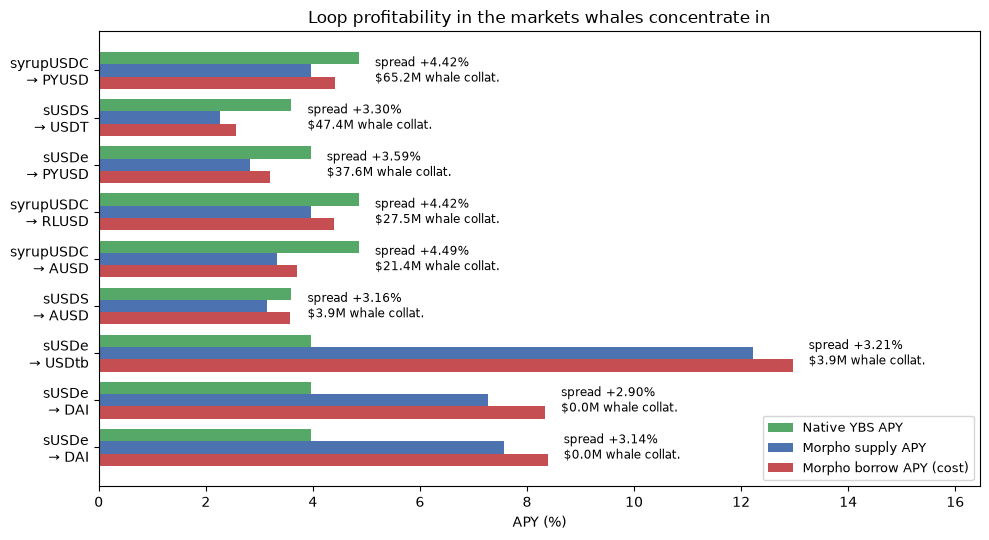

In [130]:
import matplotlib.pyplot as plt
import numpy as np

top_focus = whale_apy.merge(
    apy_table[["market_id", "native_apy", "supply_apy", "borrow_apy"]],
    on="market_id", how="left"
)
top_focus = top_focus[top_focus["whale_collateral_usd"] > 0].sort_values(
    "whale_collateral_usd", ascending=False
)

labels = [f"{r.token_name}\n\u2192 {r.loan_token_symbol}" for r in top_focus.itertuples()]
y = np.arange(len(labels))[::-1]
h = 0.26

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(y + h, top_focus["native_apy"], height=h, label="Native YBS APY", color="#55A868")
ax.barh(y, top_focus["supply_apy"], height=h, label="Morpho supply APY", color="#4C72B0")
ax.barh(y - h, top_focus["borrow_apy"], height=h, label="Morpho borrow APY (cost)", color="#C44E52")
ax.set_yticks(y)
ax.set_yticklabels(labels)
ax.set_xlabel("APY (%)")
ax.set_title("Loop profitability in the markets whales concentrate in")
for yi, row in zip(y, top_focus.itertuples()):
    m = max(row.native_apy, row.supply_apy, row.borrow_apy)
    ax.text(
        m + 0.3, yi,
        f"spread +{row.net_spread:.2f}%\n${row.whale_collateral_usd/1e6:.1f}M whale collat.",
        va="center", fontsize=8.5
    )
ax.set_xlim(0, top_focus[["native_apy", "supply_apy", "borrow_apy"]].values.max() + 3.5)
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

## Charts

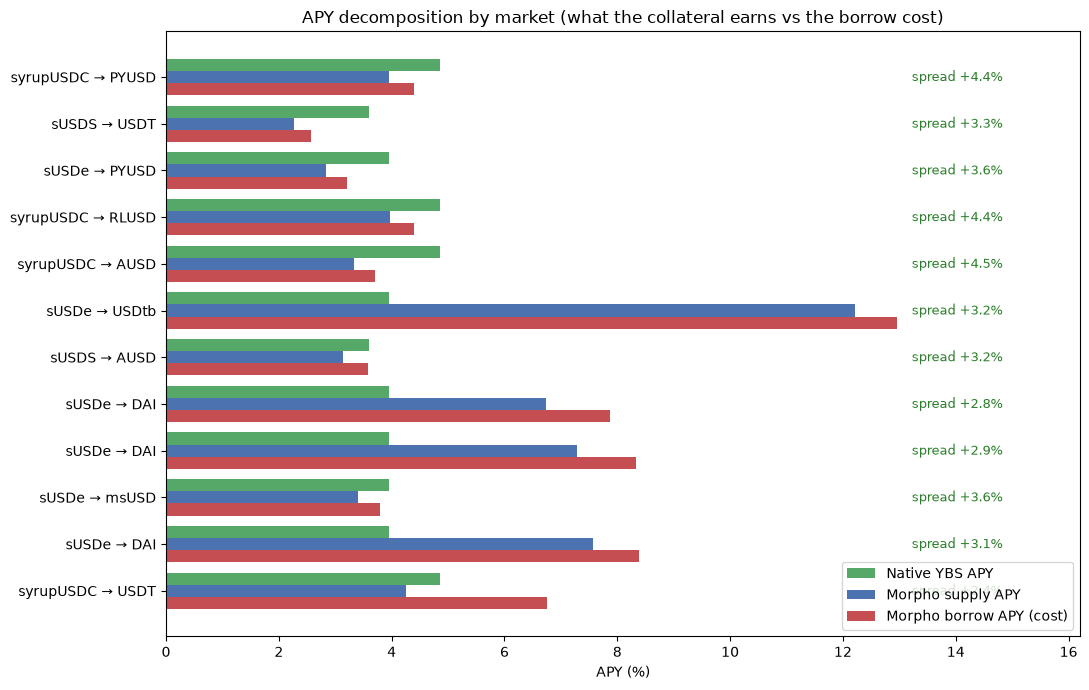

In [131]:
import matplotlib.pyplot as plt
import numpy as np

# APY decomposition for the biggest markets: what the collateral earns vs what it costs
top = apy_table.dropna(subset=["net_spread"]).head(12).iloc[::-1]   # largest at top
y = np.arange(len(top))
h = 0.26

fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(y + h, top["native_apy"], height=h, label="Native YBS APY", color="#55A868")
ax.barh(y,     top["supply_apy"], height=h, label="Morpho supply APY", color="#4C72B0")
ax.barh(y - h, top["borrow_apy"], height=h, label="Morpho borrow APY (cost)", color="#C44E52")

ax.set_yticks(y)
ax.set_yticklabels(top["market_label"])
ax.set_xlabel("APY (%)")
ax.set_title("APY decomposition by market (what the collateral earns vs the borrow cost)")
ax.legend(loc="lower right")

xmax = top[["native_apy", "supply_apy", "borrow_apy"]].max().max()
for i, s in zip(y, top["net_spread"]):
    ax.annotate(f"spread {s:+.1f}%", (xmax * 1.02, i), va="center", fontsize=9,
                color=("#2a7d2a" if s > 0 else "#b02a2a"))
ax.set_xlim(0, xmax * 1.25)

plt.tight_layout()
plt.show()

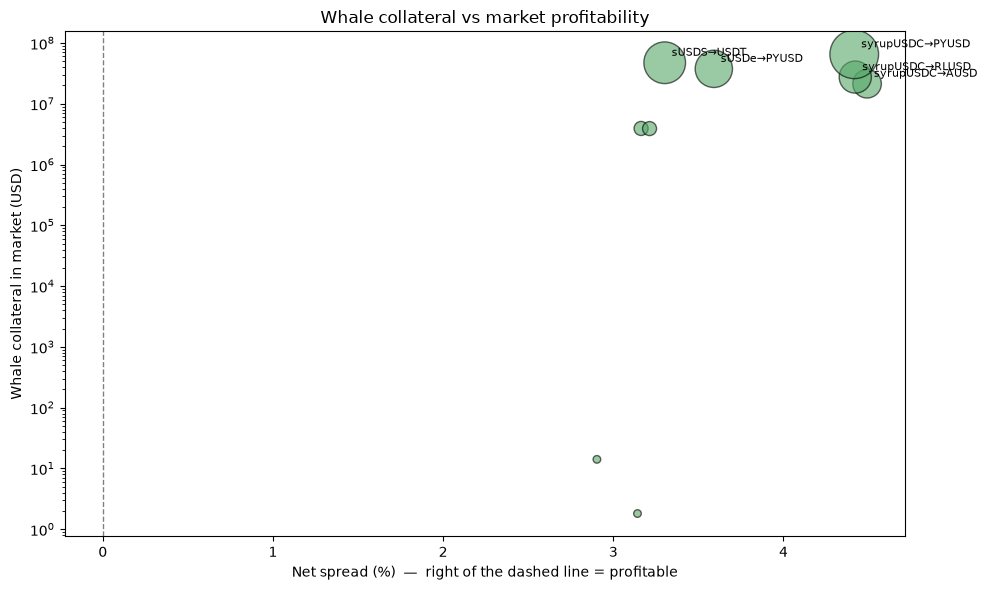

In [132]:
# do whales cluster in the profitable markets? size = whale collateral, x = net spread
plot_df = whale_apy.dropna(subset=["net_spread"])
plot_df = plot_df[plot_df["whale_collateral_usd"] > 0]

fig, ax = plt.subplots(figsize=(10, 6))
sizes = plot_df["whale_collateral_usd"] / plot_df["whale_collateral_usd"].max() * 1200 + 30
point_colors = np.where(plot_df["net_spread"] > 0, "#55A868", "#C44E52")

ax.scatter(plot_df["net_spread"], plot_df["whale_collateral_usd"], s=sizes, c=point_colors, alpha=0.6, edgecolors="k")
ax.axvline(0, color="grey", linestyle="--", linewidth=1)
ax.set_xlabel("Net spread (%)  —  right of the dashed line = profitable")
ax.set_ylabel("Whale collateral in market (USD)")
ax.set_yscale("log")
ax.set_title("Whale collateral vs market profitability")

for _, r in plot_df.sort_values("whale_collateral_usd", ascending=False).head(5).iterrows():
    ax.annotate(f"{r['token_name']}→{r['loan_token_symbol']}",
                (r["net_spread"], r["whale_collateral_usd"]), fontsize=8,
                xytext=(5, 5), textcoords="offset points")

plt.tight_layout()
plt.show()

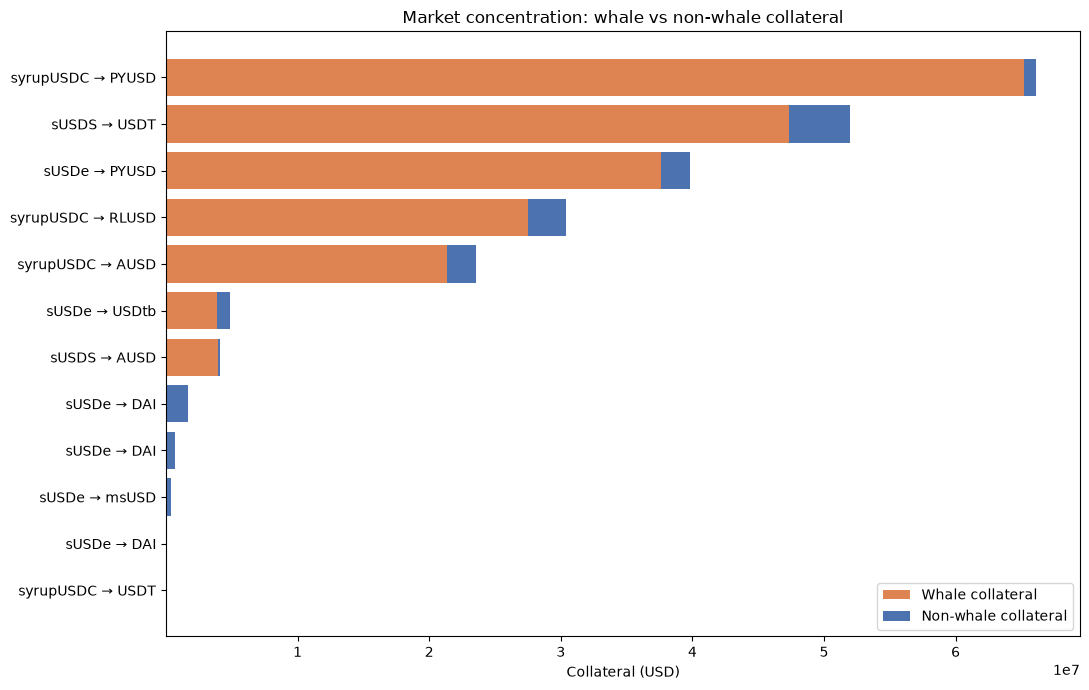

In [133]:
# market concentration split into whale vs non-whale collateral
conc = whale_market_share.copy()
conc["market_label"] = conc["token_name"] + " → " + conc["loan_token_symbol"]
conc["nonwhale_collateral_usd"] = (conc["total_collateral_usd"] - conc["whale_collateral_usd"]).clip(lower=0)
conc = conc.sort_values("total_collateral_usd", ascending=False).head(12).iloc[::-1]

y = np.arange(len(conc))
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(y, conc["whale_collateral_usd"], color="#DD8452", label="Whale collateral")
ax.barh(y, conc["nonwhale_collateral_usd"], left=conc["whale_collateral_usd"], color="#4C72B0", label="Non-whale collateral")
ax.set_yticks(y)
ax.set_yticklabels(conc["market_label"])
ax.set_xlabel("Collateral (USD)")
ax.set_title("Market concentration: whale vs non-whale collateral")
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

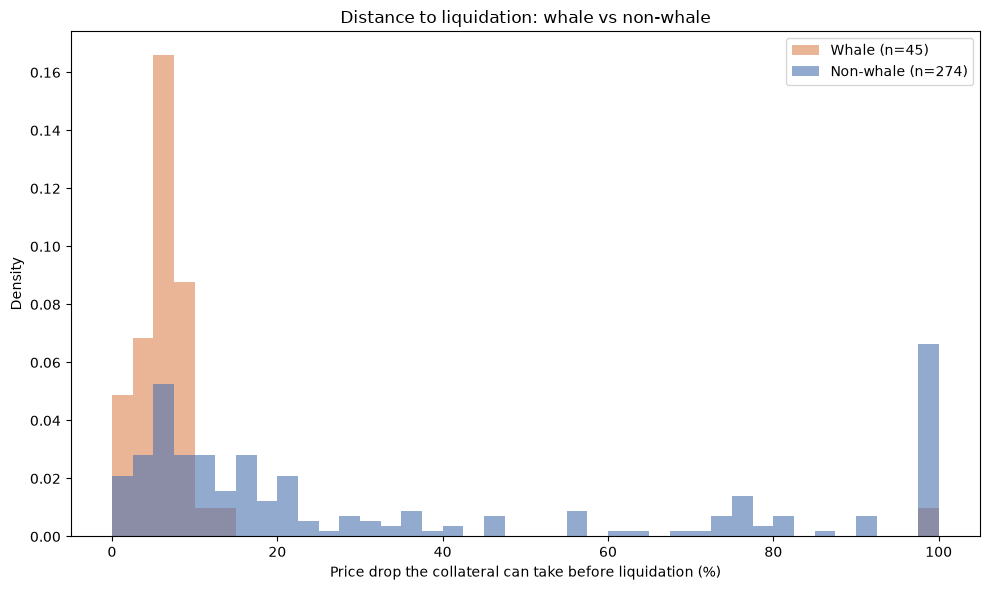

In [134]:
# how close to liquidation are positions - whale vs non-whale
fig, ax = plt.subplots(figsize=(10, 6))
bins = np.linspace(0, 100, 41)

for flag, label, color in [(True, "Whale", "#DD8452"), (False, "Non-whale", "#4C72B0")]:
    vals = lltv_clean_whales.loc[lltv_clean_whales["is_whale"] == flag, "price_drop_to_liquidation_pct"].dropna()
    ax.hist(vals, bins=bins, alpha=0.6, label=f"{label} (n={len(vals)})", color=color, density=True)

ax.set_xlabel("Price drop the collateral can take before liquidation (%)")
ax.set_ylabel("Density")
ax.set_title("Distance to liquidation: whale vs non-whale")
ax.legend()

plt.tight_layout()
plt.show()